In [1]:
print('hello')

hello


# Phase 1

## Testing which recoruces we are being used

In [2]:
import sys
print("Python executable:", sys.executable)
print("Python version:", sys.version)
print("Python path:", sys.path[:3])

Python executable: /workspaces/HouseRental/.venv/bin/python
Python version: 3.12.3 (main, Nov  6 2025, 13:44:16) [GCC 13.3.0]
Python path: ['/usr/lib/python312.zip', '/usr/lib/python3.12', '/usr/lib/python3.12/lib-dynload']


## Downloading neccessary packages

In [3]:
#pip install  pandas matplotlib numpy seaborn scikit-learn 

## Importing neccesssary packages

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

print("All packages imported successfully! ✅")
print(f"Pandas version: {pd.__version__}")
print(f"NumPy version: {np.__version__}")

All packages imported successfully! ✅
Pandas version: 2.3.3
NumPy version: 2.4.0


In [5]:
import subprocess
import sys

result = subprocess.run([sys.executable, '-m', 'pip', 'list'], capture_output=True, text=True)
print(result.stdout)

Package                 Version
----------------------- -----------
asttokens               3.0.1
comm                    0.2.3
contourpy               1.3.3
cycler                  0.12.1
debugpy                 1.8.19
decorator               5.2.1
executing               2.2.1
fonttools               4.61.1
ipykernel               7.1.0
ipython                 9.8.0
ipython_pygments_lexers 1.1.1
jedi                    0.19.2
joblib                  1.5.3
jupyter_client          8.7.0
jupyter_core            5.9.1
kiwisolver              1.4.9
matplotlib              3.10.8
matplotlib-inline       0.2.1
nest-asyncio            1.6.0
numpy                   2.4.0
packaging               25.0
pandas                  2.3.3
parso                   0.8.5
pexpect                 4.9.0
pillow                  12.0.0
pip                     25.3
platformdirs            4.5.1
prompt_toolkit          3.0.52
psutil                  7.2.1
ptyprocess              0.7.0
pure_eval               0.2

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
import joblib
from sklearn.pipeline import Pipeline
# Load the saved model

print("All packages imported successfully! ✅")
print(f"Pandas version: {pd.__version__}")
print(f"NumPy version: {np.__version__}")

All packages imported successfully! ✅
Pandas version: 2.3.3
NumPy version: 2.4.0


## load the data set

In [7]:
import os

# Relative path from notebook to CSV
csv_path = os.path.join('Sources', 'project documnet by faculty', 'House Rental.csv')

# Load data
df_raw = pd.read_csv(csv_path, low_memory=False)
df = df_raw.copy()

print(f"✅ Loaded data from: {csv_path}")
print(f"Shape: {df_raw.shape}")

✅ Loaded data from: Sources/project documnet by faculty/House Rental.csv
Shape: (99492, 22)


Problem: This won't work in containerized environments or for other team members.

Fix: Use relative paths or workspace-relative paths



In [8]:
#df_raw=pd.read_csv(r'D:\HouseRental\HouseRentalTrial-main\House Rental.csv',low_memory=False)
#df=df_raw.copy()

In [9]:
df.head()

,listing_id,listing_category,headline,description,included_features,bath_count,bed_count,payment_currency,service_fee_applicable,image_available,...,formatted_rent_text,payment_schedule,area_in_sqft,street_address,city,region_code,geo_lat,geo_lon,data_provider,listing_timestamp
0,5668640009,housing/rent/apartment,One BR 507 & 509 Esplanade,"This unit is located at 507 & 509 Esplanade, R...",NaN,1.0,1.0,USD,No,Thumbnail,...,"$2,195",Monthly,542,507 509 Esplanade,Redondo Beach,CA,33.8520,-118.3759,RentLingo,1577360355
1,5668639818,housing/rent/apartment,Three BR 146 Lochview Drive,"This unit is located at 146 Lochview Drive, Ne...",NaN,1.5,3.0,USD,No,Thumbnail,...,"$1,250",Monthly,1500,146 Lochview Dr,Newport News,VA,37.0867,-76.4941,RentLingo,1577360340
2,5668639686,housing/rent/apartment,Three BR 3101 Morningside Drive,This unit is located at 3101 Morningside Drive...,NaN,2.0,3.0,USD,No,Thumbnail,...,"$1,395",Monthly,1650,3101 Morningside Dr,Raleigh,NC,35.8230,-78.6438,RentLingo,1577360332
3,5668639659,housing/rent/apartment,Two BR 209 Aegean Way,"This unit is located at 209 Aegean Way, Vacavi...",NaN,1.0,2.0,USD,No,Thumbnail,...,"$1,600",Monthly,820,209 Aegean Way,Vacaville,CA,38.3622,-121.9712,RentLingo,1577360330
4,5668639374,housing/rent/apartment,One BR 4805 Marquette NE,"This unit is located at 4805 Marquette NE, Alb...",NaN,1.0,1.0,USD,No,Thumbnail,...,$975,Monthly,624,4805 Marquette NE,Albuquerque,NM,35.1038,-106.6110,RentLingo,1577360308


In [10]:
df.columns

Index(['listing_id', 'listing_category', 'headline', 'description',
       'included_features', 'bath_count', 'bed_count', 'payment_currency',
       'service_fee_applicable', 'image_available', 'pet_policy',
       'monthly_rent', 'formatted_rent_text', 'payment_schedule',
       'area_in_sqft', 'street_address', 'city', 'region_code', 'geo_lat',
       'geo_lon', 'data_provider', 'listing_timestamp'],
      dtype='object')

In [11]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99492 entries, 0 to 99491
Data columns (total 22 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   listing_id              99492 non-null  int64  
 1   listing_category        99492 non-null  object 
 2   headline                99492 non-null  object 
 3   description             99489 non-null  object 
 4   included_features       83448 non-null  object 
 5   bath_count              99429 non-null  float64
 6   bed_count               99368 non-null  float64
 7   payment_currency        99492 non-null  object 
 8   service_fee_applicable  99492 non-null  object 
 9   image_available         99492 non-null  object 
 10  pet_policy              39068 non-null  object 
 11  monthly_rent            99491 non-null  float64
 12  formatted_rent_text     99491 non-null  object 
 13  payment_schedule        99492 non-null  object 
 14  area_in_sqft            99492 non-null

In [12]:
df.shape

(99492, 22)

In [13]:
df.columns.tolist()

['listing_id',
 'listing_category',
 'headline',
 'description',
 'included_features',
 'bath_count',
 'bed_count',
 'payment_currency',
 'service_fee_applicable',
 'image_available',
 'pet_policy',
 'monthly_rent',
 'formatted_rent_text',
 'payment_schedule',
 'area_in_sqft',
 'street_address',
 'city',
 'region_code',
 'geo_lat',
 'geo_lon',
 'data_provider',
 'listing_timestamp']

In [14]:

numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
categorical_cols=df.select_dtypes(include=['object']).columns.tolist()

In [15]:
print("Numeric columns:", numeric_cols)
print("Categorical columns:", categorical_cols)

Numeric columns: ['listing_id', 'bath_count', 'bed_count', 'monthly_rent', 'area_in_sqft', 'geo_lat', 'geo_lon', 'listing_timestamp']
Categorical columns: ['listing_category', 'headline', 'description', 'included_features', 'payment_currency', 'service_fee_applicable', 'image_available', 'pet_policy', 'formatted_rent_text', 'payment_schedule', 'street_address', 'city', 'region_code', 'data_provider']


In [16]:
df.info(all) 

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99492 entries, 0 to 99491
Data columns (total 22 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   listing_id              99492 non-null  int64  
 1   listing_category        99492 non-null  object 
 2   headline                99492 non-null  object 
 3   description             99489 non-null  object 
 4   included_features       83448 non-null  object 
 5   bath_count              99429 non-null  float64
 6   bed_count               99368 non-null  float64
 7   payment_currency        99492 non-null  object 
 8   service_fee_applicable  99492 non-null  object 
 9   image_available         99492 non-null  object 
 10  pet_policy              39068 non-null  object 
 11  monthly_rent            99491 non-null  float64
 12  formatted_rent_text     99491 non-null  object 
 13  payment_schedule        99492 non-null  object 
 14  area_in_sqft            99492 non-null

In [17]:
df[numeric_cols].tail()

,listing_id,bath_count,bed_count,monthly_rent,area_in_sqft,geo_lat,geo_lon,listing_timestamp
99487,5121219946,1.0,1.0,780.0,605,29.6151,-95.1998,1544185770
99488,5121219696,2.0,2.0,813.0,921,30.2254,-81.7579,1544185750
99489,5121219420,1.0,1.0,1325.0,650,32.7379,-117.0914,1544185729
99490,5121218935,1.0,1.0,931.0,701,35.4158,-80.8451,1544185670
99491,5121218844,1.5,2.0,1595.0,900,32.7379,-117.0914,1544185659


In [18]:
df[categorical_cols].tail()

,listing_category,headline,description,included_features,payment_currency,service_fee_applicable,image_available,pet_policy,formatted_rent_text,payment_schedule,street_address,city,region_code,data_provider
99487,housing/rent/apartment,Houston - superb Apartment nearby fine dining,"Redefining urban living, in southeast Houston,...","Gym,Parking,Patio/Deck,Playground,Storage,Wood...",USD,No,Yes,NaN,$780,Monthly,NaN,Houston,TX,RentDigs.com
99488,housing/rent/apartment,The Best of the Best in the City of Jacksonvil...,Courtney Manor Apartments offer the best of ev...,"AC,Cable or Satellite,Clubhouse,Dishwasher,Gym...",USD,No,Yes,"Cats,Dogs",$813,Monthly,NaN,Jacksonville,FL,RentDigs.com
99489,housing/rent/apartment,A great & large One BR apartment. Pet OK!,"Fully remodeled, new floor, kitchen cabinet, s...","Garbage Disposal,Refrigerator",USD,No,Yes,"Cats,Dogs","$1,325",Monthly,NaN,San Diego,CA,RentDigs.com
99490,housing/rent/apartment,"The Crest offers studio, 1, 2 & Three BR homes...","Amenities include a fitness facilities, swimmi...","Gym,Pool",USD,No,Yes,"Cats,Dogs",$931,Monthly,NaN,Huntersville,NC,RentDigs.com
99491,housing/rent/apartment,Large Remodeled Two BR 1. Five BA Apartment Home,This is a brand new 2 Beds 1. five Bathrooms A...,"Gated,Parking,Wood Floors",USD,No,Yes,NaN,"$1,595",Monthly,NaN,San Diego,CA,RentDigs.com


In [19]:
len(numeric_cols   )

8

In [20]:
len(categorical_cols)

14

## 1.2 Column Checklist (faculty expected columns)

In [21]:

expected_cols = [
    "listing_id","listing_category","headline","description","included_features",
    "bath_count","bed_count","payment_currency","service_fee_applicable","image_available",
    "pet_policy","monthly_rent","formatted_rent_text","payment_schedule","area_in_sqft",
    "street_address","city","region_code","geo_lat","geo_lon","data_provider","listing_timestamp"
]

present = [c for c in expected_cols if c in df.columns]
missing = [c for c in expected_cols if c not in df.columns]
extra   = [c for c in df.columns if c not in expected_cols]

print("✅ Present:", len(present))
print("❌ Missing:", missing)
print("➕ Extra columns:", extra)

✅ Present: 22
❌ Missing: []
➕ Extra columns: []


## 1.3 Tag Columns by Role (target / leakage / id / risky / etc.)

In [22]:

TARGET_COL = "monthly_rent"

LEAKAGE_COLS = ["formatted_rent_text"]      # contains rent in text -> leakage
ID_COLS      = ["listing_id"]
HIGH_CARD    = ["street_address"]           # usually too high-cardinality
RAW_TEXT     = ["headline", "description", "included_features"]  # optional later (NLP)
TIME_COLS    = ["listing_timestamp"]

role_map = {}
for c in df.columns:
    if c == TARGET_COL:
        role_map[c] = "TARGET"
    elif c in LEAKAGE_COLS:
        role_map[c] = "LEAKAGE (DROP)"
    elif c in ID_COLS:
        role_map[c] = "ID (DROP)"
    elif c in HIGH_CARD:
        role_map[c] = "HIGH-CARD (DROP/LATER)"
    elif c in RAW_TEXT:
        role_map[c] = "RAW TEXT (LATER)"
    elif c in TIME_COLS:
        role_map[c] = "TIME (ENGINEER LATER)"
    else:
        role_map[c] = "FEATURE CANDIDATE"

roles_df = pd.DataFrame({
    "column": df.columns,
    "dtype": [str(df[c].dtype) for c in df.columns],
    "role": [role_map[c] for c in df.columns]
}).sort_values(["role","column"])

display(roles_df)


,column,dtype,role
14,area_in_sqft,int64,FEATURE CANDIDATE
5,bath_count,float64,FEATURE CANDIDATE
6,bed_count,float64,FEATURE CANDIDATE
16,city,object,FEATURE CANDIDATE
20,data_provider,object,FEATURE CANDIDATE
18,geo_lat,float64,FEATURE CANDIDATE
19,geo_lon,float64,FEATURE CANDIDATE
9,image_available,object,FEATURE CANDIDATE
1,listing_category,object,FEATURE CANDIDATE
7,payment_currency,object,FEATURE CANDIDATE


## 1.4 Data Types Sanity Check (critical columns)

In [23]:

key_cols = ["monthly_rent","bed_count","bath_count","area_in_sqft","geo_lat","geo_lon","listing_timestamp"]

for c in key_cols:
    if c in df.columns:
        print(f"{c:>18}  dtype={df[c].dtype}  missing={df[c].isna().sum()}")


      monthly_rent  dtype=float64  missing=1
         bed_count  dtype=float64  missing=124
        bath_count  dtype=float64  missing=63
      area_in_sqft  dtype=int64  missing=0
           geo_lat  dtype=float64  missing=25
           geo_lon  dtype=float64  missing=25
 listing_timestamp  dtype=int64  missing=0


## 1.5 Missing Values Health Report (count + %)

In [24]:

miss = df.isna().sum()
miss_pct = (miss / len(df) * 100).round(2)

missing_report = (pd.DataFrame({
    "missing_count": miss,
    "missing_pct": miss_pct
})
.sort_values("missing_pct", ascending=False))

display(missing_report.head(15))


,missing_count,missing_pct
street_address,91549,92.02
pet_policy,60424,60.73
included_features,16044,16.13
city,302,0.30
region_code,302,0.30
bed_count,124,0.12
bath_count,63,0.06
geo_lat,25,0.03
geo_lon,25,0.03
listing_category,0,0.00


## 1.6 Duplicate Checks (rows + listing_id)

In [25]:

dup_rows = df.duplicated().sum()
print("Duplicate rows:", dup_rows)

if "listing_id" in df.columns:
    dup_ids = df["listing_id"].duplicated().sum()
    print("Duplicate listing_id:", dup_ids)


Duplicate rows: 84
Duplicate listing_id: 84


## 1.7 Quick Value Sanity (target + numeric ranges)

In [26]:

# Target checks
if TARGET_COL in df.columns:
    y = pd.to_numeric(df[TARGET_COL], errors="coerce")
    print("Target (monthly_rent) summary:")
    display(y.describe())

    print("Non-positive rent count (<=0):", (y <= 0).sum())
    print("Missing/invalid rent count:", y.isna().sum())

# Geo sanity
if "geo_lat" in df.columns and "geo_lon" in df.columns:
    lat = pd.to_numeric(df["geo_lat"], errors="coerce")
    lon = pd.to_numeric(df["geo_lon"], errors="coerce")

    bad_lat = ((lat < -90) | (lat > 90)).sum()
    bad_lon = ((lon < -180) | (lon > 180)).sum()

    print("Bad latitude count:", bad_lat)
    print("Bad longitude count:", bad_lon)

# Beds/Baths sanity
for c in ["bed_count","bath_count","area_in_sqft"]:
    if c in df.columns:
        s = pd.to_numeric(df[c], errors="coerce")
        print(f"\n{c} summary:")
        display(s.describe())


Target (monthly_rent) summary:


count    99491.000000
mean      1527.057281
std        904.245882
min        100.000000
25%       1013.000000
50%       1350.000000
75%       1795.000000
max      52500.000000
Name: monthly_rent, dtype: float64

Non-positive rent count (<=0): 0
Missing/invalid rent count: 1
Bad latitude count: 0
Bad longitude count: 0

bed_count summary:


count    99368.000000
mean         1.728212
std          0.749200
min          0.000000
25%          1.000000
50%          2.000000
75%          2.000000
max          9.000000
Name: bed_count, dtype: float64


bath_count summary:


count    99429.000000
mean         1.445323
std          0.547021
min          1.000000
25%          1.000000
50%          1.000000
75%          2.000000
max          9.000000
Name: bath_count, dtype: float64


area_in_sqft summary:


count    99492.000000
mean       956.430688
std        417.571522
min        101.000000
25%        729.000000
50%        900.000000
75%       1115.000000
max      50000.000000
Name: area_in_sqft, dtype: float64

## 1.8 Cardinality Report (unique counts for categoricals)

In [27]:

cat_cols = [c for c in df.columns if df[c].dtype == "object"]

card = pd.DataFrame({
    "column": cat_cols,
    "nunique": [df[c].nunique(dropna=True) for c in cat_cols],
    "top_value": [df[c].value_counts(dropna=True).head(1).index[0] if df[c].notna().any() else None for c in cat_cols],
    "top_freq":  [df[c].value_counts(dropna=True).head(1).iloc[0] if df[c].notna().any() else None for c in cat_cols],
}).sort_values("nunique", ascending=False)

display(card)


,column,nunique,top_value,top_freq
2,description,94500,"When searching for a pet-friendly One-, Two- a...",43
1,headline,58503,Apartment in great location,1064
3,included_features,9827,Parking,6188
10,street_address,7771,8215 S.W 72nd Avenue,19
8,formatted_rent_text,3718,"$1,350",574
11,city,2979,Dallas,2858
12,region_code,51,TX,11257
13,data_provider,25,RentDigs.com,90912
0,listing_category,7,housing/rent/apartment,99431
7,pet_policy,4,"Cats,Dogs",37097


## 1.9 Timestamp Readiness (min/max date)

In [28]:

if "listing_timestamp" in df.columns:
    ts = pd.to_numeric(df["listing_timestamp"], errors="coerce")
    dt = pd.to_datetime(ts, unit="s", errors="coerce")

    print("Timestamp missing/invalid:", dt.isna().sum())
    print("Min date:", dt.min())
    print("Max date:", dt.max())


Timestamp missing/invalid: 0
Min date: 2018-12-07 09:20:18
Max date: 2019-12-26 20:17:05


## 1.10 Phase 1 Summary (one neat table for faculty)

In [29]:
summary = pd.DataFrame({
    "column": df.columns,
    "dtype": [str(df[c].dtype) for c in df.columns],
    "role": [role_map[c] for c in df.columns],
    "missing_pct": [(df[c].isna().mean()*100).round(2) for c in df.columns],
    "nunique": [df[c].nunique(dropna=True) for c in df.columns],
}).sort_values(["role","missing_pct"], ascending=[True, False])

display(summary)

,column,dtype,role,missing_pct,nunique
10,pet_policy,object,FEATURE CANDIDATE,60.73,4
16,city,object,FEATURE CANDIDATE,0.30,2979
17,region_code,object,FEATURE CANDIDATE,0.30,51
6,bed_count,float64,FEATURE CANDIDATE,0.12,10
5,bath_count,float64,FEATURE CANDIDATE,0.06,16
18,geo_lat,float64,FEATURE CANDIDATE,0.03,7212
19,geo_lon,float64,FEATURE CANDIDATE,0.03,7270
1,listing_category,object,FEATURE CANDIDATE,0.00,7
7,payment_currency,object,FEATURE CANDIDATE,0.00,1
8,service_fee_applicable,object,FEATURE CANDIDATE,0.00,2


# Phase 2


## PHASE 2: Cleaning + Leakage Removal + Type Fixes


In [30]:

df1 = df_raw.copy()
print("Phase 2 start shape:", df1.shape)

TARGET_COL = "monthly_rent"

LEAKAGE_COLS = ["formatted_rent_text"]   # rent info hidden in text -> leakage
ID_COLS      = ["listing_id"]           # identifier
CONSTANT_COLS = ["payment_currency"]    # usually constant
HIGH_MISSING_OR_HIGH_CARD = ["street_address"]  # 92% missing + high-cardinality in your data
RAW_TEXT_COLS = ["headline", "description"]     # optional; usually dropped for tabular baseline

Phase 2 start shape: (99492, 22)


## Phase 2.1 — “Receipts” check (so decisions are evidence-based)

In [31]:

def quick_col_stats(df, cols):
    rows = []
    for c in cols:
        if c in df.columns:
            rows.append({
                "col": c,
                "dtype": str(df[c].dtype),
                "missing_pct": round(df[c].isna().mean()*100, 2),
                "nunique": df[c].nunique(dropna=True)
            })
    return pd.DataFrame(rows).sort_values("missing_pct", ascending=False)

check_cols = LEAKAGE_COLS + ID_COLS + CONSTANT_COLS + HIGH_MISSING_OR_HIGH_CARD + RAW_TEXT_COLS + ["city", "region_code", "included_features"]
display(quick_col_stats(df1, check_cols))



,col,dtype,missing_pct,nunique
3,street_address,object,92.02,7771
8,included_features,object,16.13,9827
6,city,object,0.30,2979
7,region_code,object,0.30,51
0,formatted_rent_text,object,0.00,3718
4,headline,object,0.00,58503
2,payment_currency,object,0.00,1
1,listing_id,int64,0.00,99408
5,description,object,0.00,94500


## ✅ Phase 2.2 — Deduplicate (do this BEFORE dropping listing_id)

In [32]:

print("Duplicate rows:", df.duplicated().sum())

if "listing_id" in df1.columns:
    print("Duplicate listing_id:", df1["listing_id"].duplicated().sum())
    before = len(df1)
    df1 = df1.drop_duplicates(subset=["listing_id"], keep="first")
    print("Dropped duplicates by listing_id:", before - len(df1))

print("After dedupe shape:", df1.shape)

Duplicate rows: 84
Duplicate listing_id: 84
Dropped duplicates by listing_id: 84
After dedupe shape: (99408, 22)


## ✅ Phase 2.3 — Separate “training rows” (don’t mix target-missing rows)


This keeps your notebook clean: we will train only on rows where target exists.



In [33]:

print("Missing target rows:", df1[TARGET_COL].isna().sum())

df_train = df1.dropna(subset=[TARGET_COL]).copy()
print("Training shape (target present):", df_train.shape)

Missing target rows: 1
Training shape (target present): (99407, 22)


## ✅ Phase 2.4 — Drop leakage + junk columns (on df_train)

Decision logic (from your Phase 1 stats):

formatted_rent_text → leakage

listing_id → ID

payment_currency → constant

street_address → too much missing + too many uniques

headline/description → huge cardinality text (we’ll skip in tabular pipeline; can be “Phase 4/extra” later)


In [34]:

DROP_NOW = []
for c in (LEAKAGE_COLS + ID_COLS + CONSTANT_COLS + HIGH_MISSING_OR_HIGH_CARD + RAW_TEXT_COLS):
    if c in df_train.columns:
        DROP_NOW.append(c)

df_train = df_train.drop(columns=DROP_NOW, errors="ignore")
print("Dropped columns:", DROP_NOW)
print("After drop shape:", df_train.shape)



Dropped columns: ['formatted_rent_text', 'listing_id', 'payment_currency', 'street_address', 'headline', 'description']
After drop shape: (99407, 16)


## ✅ Phase 2.5 — Fix numeric types (coerce bad values to NaN)

In [35]:

numeric_cols = ["monthly_rent","bed_count","bath_count","area_in_sqft","geo_lat","geo_lon","listing_timestamp"]

for c in numeric_cols:
    if c in df_train.columns:
        df_train[c] = pd.to_numeric(df_train[c], errors="coerce")

display(df_train[[c for c in numeric_cols if c in df_train.columns]].dtypes)



monthly_rent         float64
bed_count            float64
bath_count           float64
area_in_sqft           int64
geo_lat              float64
geo_lon              float64
listing_timestamp      int64
dtype: object

## ✅ Phase 2.6 — Clean categorical strings + standardize missing tokens

This is safe because we’re not “learning” from data; we’re just cleaning text.

In [36]:


cat_cols = [c for c in df_train.columns if df_train[c].dtype == "object"]

MISSING_TOKENS = {"", " ", "nan", "none", "null", "na", "n/a"}

for c in cat_cols:
    s = df_train[c].astype("string")
    s = s.str.strip()
    s = s.str.replace(r"\s+", " ", regex=True)
    s_lower = s.str.lower()
    s = s.mask(s_lower.isin(MISSING_TOKENS), pd.NA)
    df_train[c] = s
    print(f"Column '{c}': cleaned missing count = {df_train[c].isna().sum()}")


Column 'listing_category': cleaned missing count = 0
Column 'included_features': cleaned missing count = 16034
Column 'service_fee_applicable': cleaned missing count = 0
Column 'image_available': cleaned missing count = 0
Column 'pet_policy': cleaned missing count = 60374
Column 'payment_schedule': cleaned missing count = 0
Column 'city': cleaned missing count = 302
Column 'region_code': cleaned missing count = 302
Column 'data_provider': cleaned missing count = 0


## ✅ Phase 2.7 — Fill categorical missing as "Unknown" (important for pet_policy)

In [37]:

cat_cols = [c for c in df_train.columns if str(df_train[c].dtype) in ("object", "string")]
for c in cat_cols:
    df_train[c] = df_train[c].fillna("Unknown")

# Special handling for amenities text (prep for Phase 4 amenity_count)
if "included_features" in df_train.columns:
    df_train["included_features"] = df_train["included_features"].replace("Unknown", "")

## ✅ Phase 2.8 — Numeric missing report (don’t impute yet)

We only report. Median/mean imputation must be done after split (Phase 6 pipeline).


In [38]:

num_present = [c for c in numeric_cols if c in df_train.columns]
missing_numeric_pct = (df_train[num_present].isna().mean() * 100).round(3).sort_values(ascending=False)
print("Numeric missing % (Phase 2):")
display(missing_numeric_pct)

Numeric missing % (Phase 2):


bed_count            0.125
bath_count           0.063
geo_lat              0.025
geo_lon              0.025
monthly_rent         0.000
area_in_sqft         0.000
listing_timestamp    0.000
dtype: float64

## ✅ Phase 2.9 — Timestamp validity check (no feature engineering yet)

In [39]:

if "listing_timestamp" in df_train.columns:
    dt = pd.to_datetime(df_train["listing_timestamp"], unit="s", errors="coerce")
    print("Invalid timestamps:", dt.isna().sum())
    print("Min date:", dt.min())
    print("Max date:", dt.max())


Invalid timestamps: 0
Min date: 2018-12-07 09:20:18
Max date: 2019-12-26 20:17:05


## 2.10 — Phase 2 Exit Report (faculty-friendly)

In [40]:

print("PHASE 2 FINAL SHAPE:", df_train.shape)

phase2_report = pd.DataFrame({
    "dtype": df_train.dtypes.astype(str),
    "missing_pct": (df_train.isna().mean()*100).round(2),
    "nunique": df_train.nunique(dropna=True)
}).sort_values("missing_pct", ascending=False)

display(phase2_report.head(20))

PHASE 2 FINAL SHAPE: (99407, 16)


,dtype,missing_pct,nunique
bed_count,float64,0.12,10
bath_count,float64,0.06,16
geo_lat,float64,0.03,7212
geo_lon,float64,0.03,7270
service_fee_applicable,string,0.00,2
image_available,string,0.00,3
included_features,string,0.00,9828
listing_category,string,0.00,7
monthly_rent,float64,0.00,3687
pet_policy,string,0.00,5


# Phase 3
## 3.0 Setup (imports + working copy)

In [41]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df_eda = df_train.copy()
print("EDA shape:", df_eda.shape)
display(df_eda.head(3))

EDA shape: (99407, 16)


,listing_category,included_features,bath_count,bed_count,service_fee_applicable,image_available,pet_policy,monthly_rent,payment_schedule,area_in_sqft,city,region_code,geo_lat,geo_lon,data_provider,listing_timestamp
0,housing/rent/apartment,,1.0,1.0,No,Thumbnail,Cats,2195.0,Monthly,542,Redondo Beach,CA,33.8520,-118.3759,RentLingo,1577360355
1,housing/rent/apartment,,1.5,3.0,No,Thumbnail,"Cats,Dogs",1250.0,Monthly,1500,Newport News,VA,37.0867,-76.4941,RentLingo,1577360340
2,housing/rent/apartment,,2.0,3.0,No,Thumbnail,Unknown,1395.0,Monthly,1650,Raleigh,NC,35.8230,-78.6438,RentLingo,1577360332


## 3.1 Quick dataset snapshot (types + missing)

In [42]:

display(df_eda.dtypes)

missing = (df_eda.isna().mean()*100).round(2).sort_values(ascending=False)
print("Missing %:")
display(missing[missing > 0])

listing_category          string[python]
included_features         string[python]
bath_count                       float64
bed_count                        float64
service_fee_applicable    string[python]
image_available           string[python]
pet_policy                string[python]
monthly_rent                     float64
payment_schedule          string[python]
area_in_sqft                       int64
city                      string[python]
region_code               string[python]
geo_lat                          float64
geo_lon                          float64
data_provider             string[python]
listing_timestamp                  int64
dtype: object

Missing %:


bed_count     0.12
bath_count    0.06
geo_lat       0.03
geo_lon       0.03
dtype: float64

## 3.2 Target distribution: monthly_rent (most important plot)

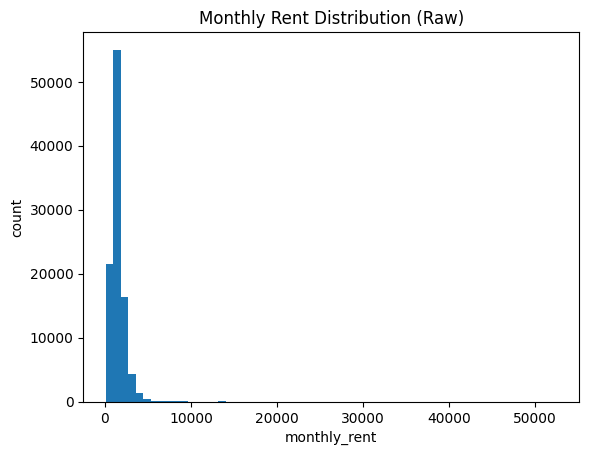

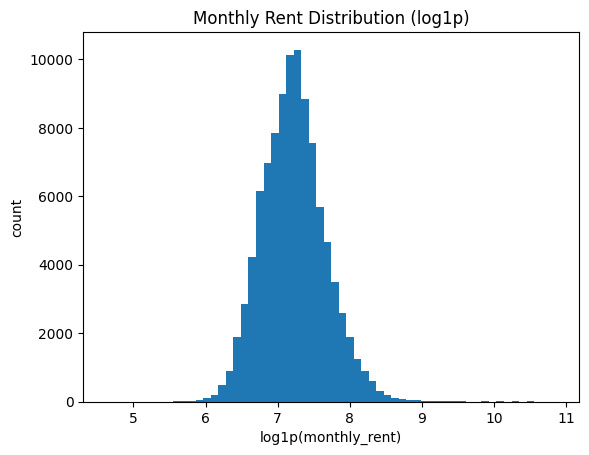

Rent summary:


count    99407.000000
mean      1527.076403
std        904.372903
min        100.000000
25%       1013.500000
50%       1350.000000
75%       1795.000000
max      52500.000000
Name: monthly_rent, dtype: float64

Skewness: 9.962559499192134


In [43]:

y = df_eda["monthly_rent"].dropna()

plt.figure()
plt.hist(y, bins=60)
plt.title("Monthly Rent Distribution (Raw)")
plt.xlabel("monthly_rent")
plt.ylabel("count")
plt.show()

# Log view (helps if right-skewed)
plt.figure()
plt.hist(np.log1p(y), bins=60)
plt.title("Monthly Rent Distribution (log1p)")
plt.xlabel("log1p(monthly_rent)")
plt.ylabel("count")
plt.show()

print("Rent summary:")
display(y.describe())
print("Skewness:", y.skew())



### Decision this informs:

- If skew is high → consider log transform target for regression (optional).

## 3.3 Outliers check (quantiles, not deletion yet)

Rent quantiles:


0.500    1350.0
0.750    1795.0
0.900    2411.0
0.950    2925.0
0.990    4250.0
0.995    5000.0
0.999    9000.0
Name: monthly_rent, dtype: float64

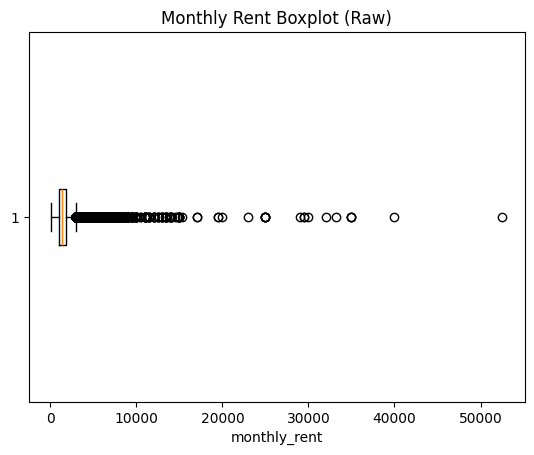

In [44]:

q = y.quantile([0.50, 0.75, 0.90, 0.95, 0.99, 0.995, 0.999])
print("Rent quantiles:")
display(q)

# Simple boxplot to visualize extremes
plt.figure()
plt.boxplot(y, vert=False)
plt.title("Monthly Rent Boxplot (Raw)")
plt.xlabel("monthly_rent")
plt.show()

Decision this informs:
- If top 1% is crazy high → prefer capping or log target, not mass deletion.

## 3.4 Numeric relationships with rent (beds, baths, area, geo)
### 3.4.1 Rent vs Area (scatter)

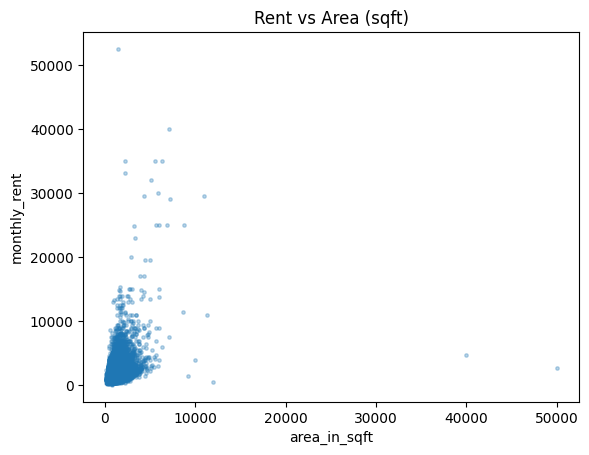

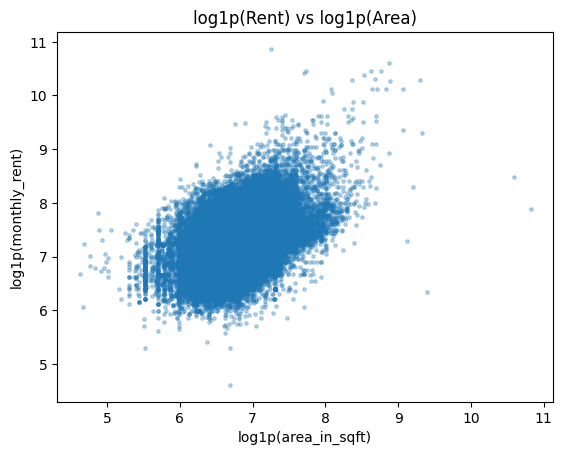

In [45]:

if "area_in_sqft" in df_eda.columns:
    x = df_eda["area_in_sqft"]
    plt.figure()
    plt.scatter(x, df_eda["monthly_rent"], s=6, alpha=0.3)
    plt.title("Rent vs Area (sqft)")
    plt.xlabel("area_in_sqft")
    plt.ylabel("monthly_rent")
    plt.show()

    # log-log view (often clearer)
    plt.figure()
    plt.scatter(np.log1p(x), np.log1p(df_eda["monthly_rent"]), s=6, alpha=0.3)
    plt.title("log1p(Rent) vs log1p(Area)")
    plt.xlabel("log1p(area_in_sqft)")
    plt.ylabel("log1p(monthly_rent)")
    plt.show()


## 3.4.2 Rent by bed_count / bath_count (boxplots)

/tmp/ipykernel_141266/3434070896.py:10: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(data, labels=[str(v) for v in sorted(top_vals)], showfliers=False)


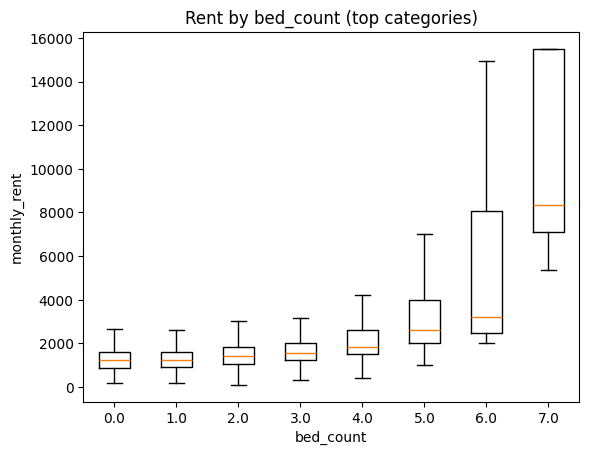

/tmp/ipykernel_141266/3434070896.py:10: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(data, labels=[str(v) for v in sorted(top_vals)], showfliers=False)


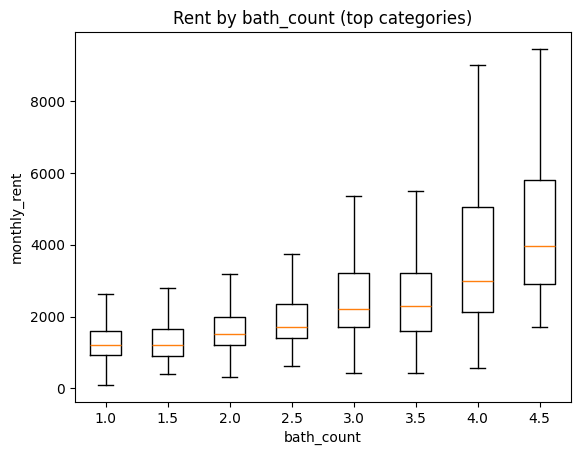

In [46]:
for col in ["bed_count", "bath_count"]:
    if col in df_eda.columns:
        tmp = df_eda[[col, "monthly_rent"]].dropna()
        # keep top few categories (beds can have rare huge values)
        top_vals = tmp[col].value_counts().head(8).index.tolist()
        tmp = tmp[tmp[col].isin(top_vals)]

        data = [tmp[tmp[col]==v]["monthly_rent"].values for v in sorted(top_vals)]
        plt.figure()
        plt.boxplot(data, labels=[str(v) for v in sorted(top_vals)], showfliers=False)
        plt.title(f"Rent by {col} (top categories)")
        plt.xlabel(col)
        plt.ylabel("monthly_rent")
        plt.show()




Decision this informs:

Confirms whether beds/baths/area are strong predictors.

Also shows weird categories (like bed_count=10) that might need capping.

## 3.5 Categorical impact (location + policies)
### 3.5.1 Top cities by count

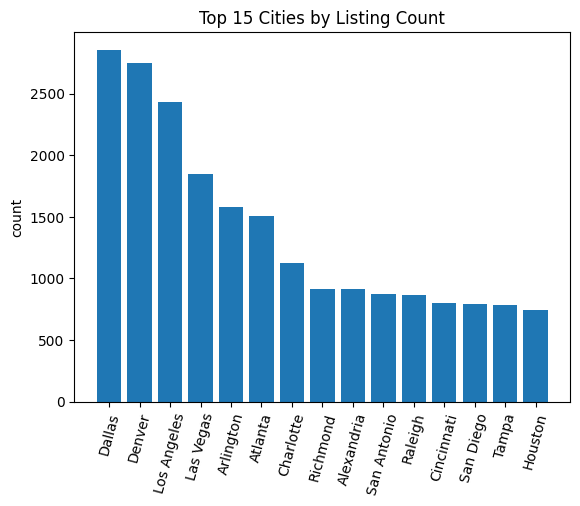

In [47]:

if "city" in df_eda.columns:
    city_counts = df_eda["city"].value_counts().head(15)
    plt.figure()
    plt.bar(city_counts.index.astype(str), city_counts.values)
    plt.title("Top 15 Cities by Listing Count")
    plt.xticks(rotation=75)
    plt.ylabel("count")
    plt.show()


### 3.5.2 Top cities by median rent (only cities with enough samples)

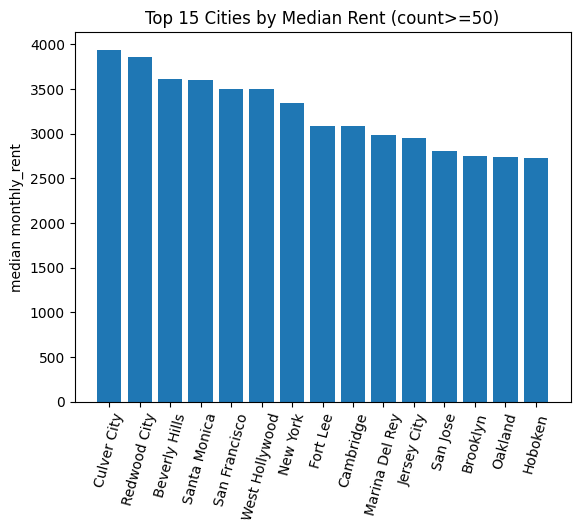

,city,count,median
611,Culver City,101,3940.0
2203,Redwood City,51,3855.0
219,Beverly Hills,58,3608.5
2367,Santa Monica,161,3600.0
2340,San Francisco,133,3500.0
2836,West Hollywood,78,3497.5
1819,New York,169,3350.0
903,Fort Lee,50,3089.5
362,Cambridge,146,3084.5
1571,Marina Del Rey,90,2985.0


In [48]:
if "city" in df_eda.columns:
    city_stats = df_eda.groupby("city")["monthly_rent"].agg(["count", "median"]).reset_index()
    city_stats = city_stats[city_stats["count"] >= 50].sort_values("median", ascending=False).head(15)

    plt.figure()
    plt.bar(city_stats["city"].astype(str), city_stats["median"])
    plt.title("Top 15 Cities by Median Rent (count>=50)")
    plt.xticks(rotation=75)
    plt.ylabel("median monthly_rent")
    plt.show()

    display(city_stats)


### 3.5.3 Region impact

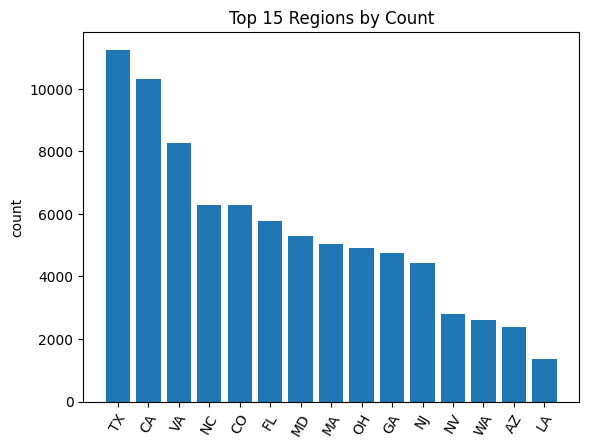

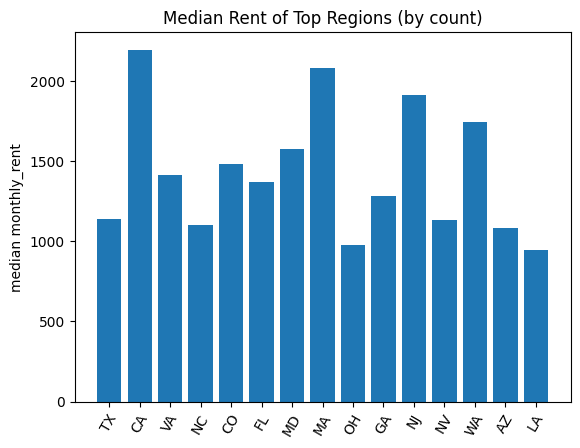

,region_code,count,median
43,TX,11250,1140.0
4,CA,10301,2195.0
46,VA,8278,1411.0
27,NC,6293,1099.0
5,CO,6279,1479.0
9,FL,5772,1372.0
20,MD,5276,1576.0
19,MA,5023,2080.0
35,OH,4899,979.0
10,GA,4750,1285.0


In [49]:
if "region_code" in df_eda.columns:
    reg_stats = df_eda.groupby("region_code")["monthly_rent"].agg(["count","median"]).reset_index()
    reg_stats = reg_stats.sort_values("count", ascending=False).head(15)

    plt.figure()
    plt.bar(reg_stats["region_code"].astype(str), reg_stats["count"])
    plt.title("Top 15 Regions by Count")
    plt.xticks(rotation=60)
    plt.ylabel("count")
    plt.show()

    plt.figure()
    plt.bar(reg_stats["region_code"].astype(str), reg_stats["median"])
    plt.title("Median Rent of Top Regions (by count)")
    plt.xticks(rotation=60)
    plt.ylabel("median monthly_rent")
    plt.show()

    display(reg_stats)


### 3.5.4 Policy features (pet_policy, payment_schedule)

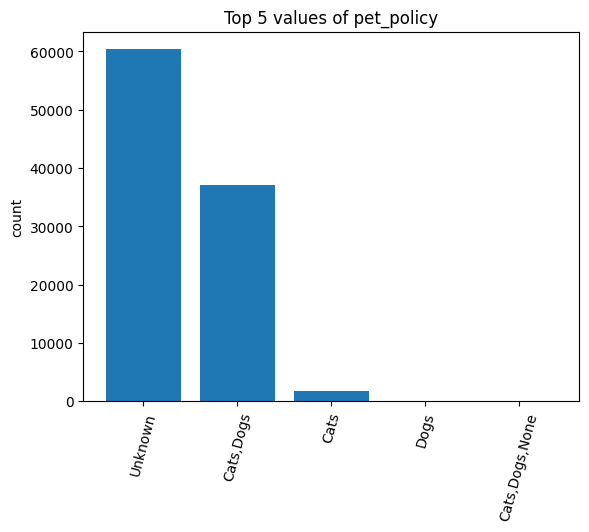

,pet_policy,count,median
3,Dogs,127,1795.0
4,Unknown,60374,1385.0
1,"Cats,Dogs",37065,1310.0
0,Cats,1840,1250.0


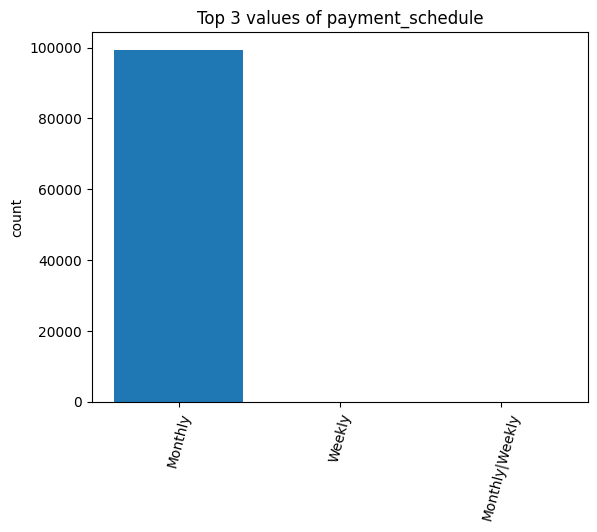

,payment_schedule,count,median
0,Monthly,99403,1350.0


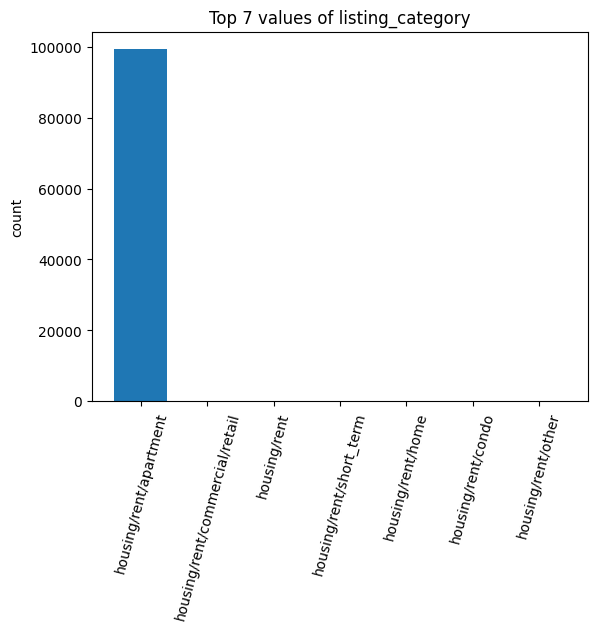

,listing_category,count,median
1,housing/rent/apartment,99346,1350.0


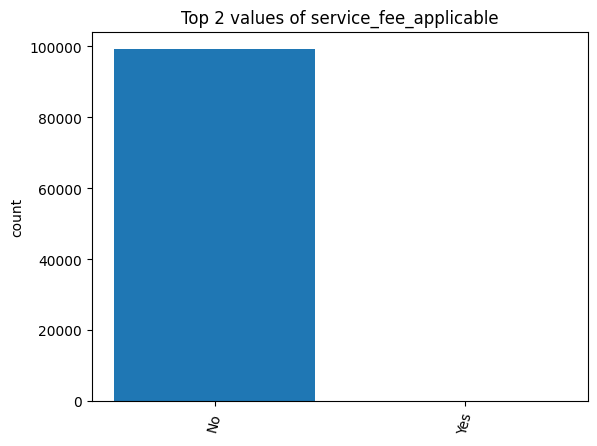

,service_fee_applicable,count,median
1,Yes,201,1800.0
0,No,99206,1350.0


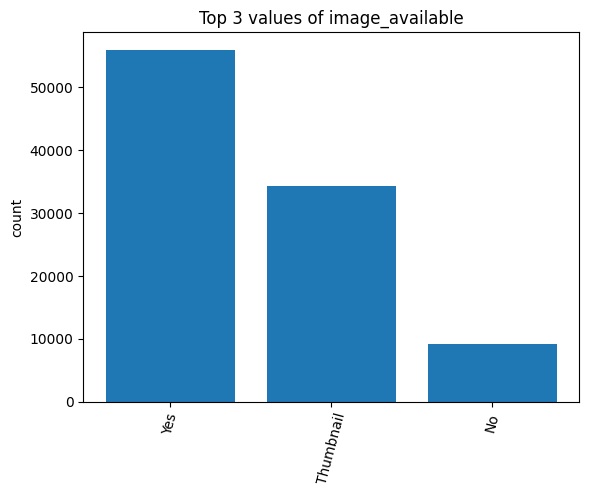

,image_available,count,median
0,No,9198,1431.5
2,Yes,55908,1371.0
1,Thumbnail,34301,1300.0


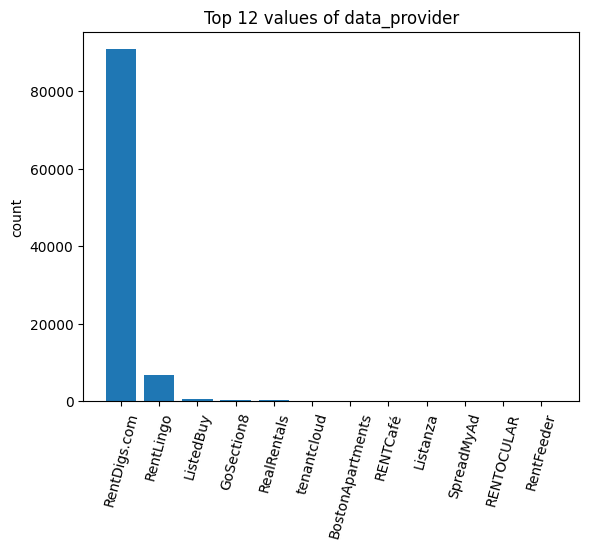

,data_provider,count,median
2,BostonApartments,94,2807.5
15,RealRentals,268,1729.5
16,RentDigs.com,90827,1365.0
18,RentLingo,6924,1240.0
9,ListedBuy,571,980.0
5,GoSection8,437,950.0
23,tenantcloud,124,912.5


'\nDecisions this informs:\n\nCity is high-cardinality → we will group rare cities in Phase 6 (encoder step).\n\nWhich categoricals are useful vs noisy.\n'

In [50]:

for col in ["pet_policy", "payment_schedule", "listing_category", "service_fee_applicable", "image_available", "data_provider"]:
    if col in df_eda.columns:
        vc = df_eda[col].value_counts().head(12)
        plt.figure()
        plt.bar(vc.index.astype(str), vc.values)
        plt.title(f"Top {min(12,len(vc))} values of {col}")
        plt.xticks(rotation=75)
        plt.ylabel("count")
        plt.show()

        # Median rent by category (only for frequent categories)
        stats = df_eda.groupby(col)["monthly_rent"].agg(["count","median"]).reset_index()
        stats = stats[stats["count"] >= 50].sort_values("median", ascending=False).head(12)
        display(stats)

'''
Decisions this informs:

City is high-cardinality → we will group rare cities in Phase 6 (encoder step).

Which categoricals are useful vs noisy.
'''

## 3.6 Time analysis (timestamp sanity + monthly trend)

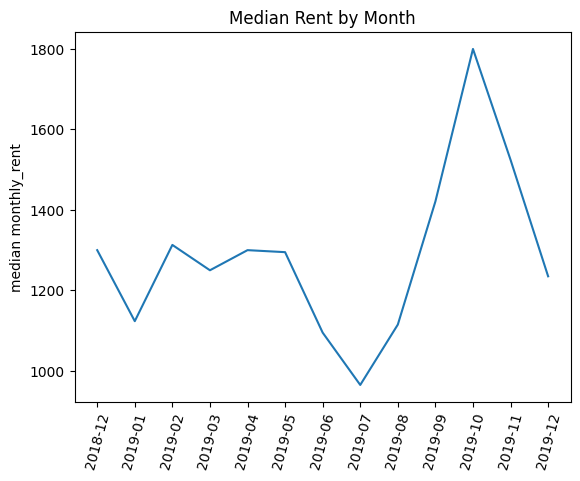

,listing_month,monthly_rent
0,2018-12,1300.0
1,2019-01,1123.5
2,2019-02,1313.0
3,2019-03,1250.0
4,2019-04,1300.0


'\n\nDecision this informs:\n\nIf rents change over months → time features (month) can help.\n'

In [51]:

if "listing_timestamp" in df_eda.columns:
    dt = pd.to_datetime(df_eda["listing_timestamp"], unit="s", errors="coerce")
    df_eda["listing_date"] = dt
    df_eda["listing_month"] = df_eda["listing_date"].dt.to_period("M").astype(str)

    monthly = df_eda.groupby("listing_month")["monthly_rent"].median().reset_index()

    plt.figure()
    plt.plot(monthly["listing_month"], monthly["monthly_rent"])
    plt.title("Median Rent by Month")
    plt.xticks(rotation=75)
    plt.ylabel("median monthly_rent")
    plt.show()

    display(monthly.head())
'''

Decision this informs:

If rents change over months → time features (month) can help.
'''

## 3.7 Correlation (numeric only)

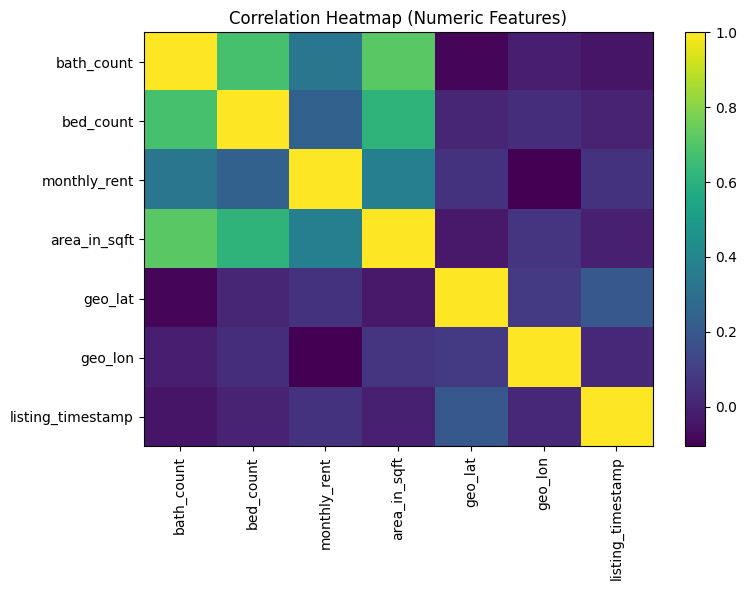

monthly_rent         1.000000
area_in_sqft         0.371692
bath_count           0.329884
bed_count            0.237226
listing_timestamp    0.056861
geo_lat              0.056760
geo_lon             -0.106366
Name: monthly_rent, dtype: float64

'\n\nDecision this informs:\n\nWhich numeric features are strongly related to rent.'

In [52]:

num_cols = [c for c in df_eda.columns if pd.api.types.is_numeric_dtype(df_eda[c])]
corr = df_eda[num_cols].corr(numeric_only=True)

plt.figure(figsize=(8,6))
plt.imshow(corr, aspect="auto")
plt.colorbar()
plt.title("Correlation Heatmap (Numeric Features)")
plt.xticks(range(len(num_cols)), num_cols, rotation=90)
plt.yticks(range(len(num_cols)), num_cols)
plt.tight_layout()
plt.show()

display(corr["monthly_rent"].sort_values(ascending=False))
'''

Decision this informs:

Which numeric features are strongly related to rent.'''

# Phase 4: Feature Engineering

**Goal**: Create NEW features from raw data to help predict rent.

We will:
1. Extract amenity features from `included_features` text
2. Create ratio features (beds/baths)
3. Extract time features from `listing_timestamp`

## Phase 4.1  Amenity Features (Text Extraction)
- Goal: Extract useful info from included_features text column.

In [57]:
# ============================================================
# 4.1.1 AMENITY DISCOVERY - Find all amenities in the data
# ============================================================

# Prepare text column
s = df_train["included_features"].astype("string").fillna("")

# Split, explode, clean
all_amenities = (
    s.str.split(",")
    .explode()
    .str.strip()
    .str.replace(r"\s+", " ", regex=True)
)

# Remove empty strings
all_amenities = all_amenities[all_amenities != ""]

# Count frequencies
amenity_counts = all_amenities.value_counts()

print(f"✅ Total unique amenities found: {len(amenity_counts)}")
print(f"\n📊  amenities:")
print(amenity_counts.head(len(amenity_counts)))

✅ Total unique amenities found: 27

📊  amenities:
included_features
Parking               43766
Pool                  43455
Gym                   37242
Patio/Deck            26480
Washer Dryer          25934
Storage               21572
Clubhouse             19050
Dishwasher            16578
AC                    15758
Refrigerator          14893
Fireplace             14885
Cable or Satellite    12505
Playground            11315
Internet Access       11046
Wood Floors            8870
Gated                  8651
Tennis                 8467
TV                     4469
Elevator               4315
Basketball             4132
Hot Tub                3993
Garbage Disposal       3871
View                   2086
Alarm                   364
Doorman                 217
Luxury                  210
Golf                     27
Name: count, dtype: int64


### 4.1.2 Amenity Encoding
**Goal:** Convert selected amenities into binary features.

In [63]:
# 4.1.2 Amenity Encoding

import re

# Keep all amenities discovered (no thresholding)
final_amenities = amenity_counts.index.tolist()

print(f"Amenities kept for modeling: {len(final_amenities)}")
print(final_amenities[:25])

s = df_train["included_features"].astype("string").fillna("")

amenity_cols = []
for amenity in final_amenities:
    safe_name = re.sub(r"[^A-Za-z0-9_]+", "_", amenity).strip("_")
    safe_name = re.sub(r"_+", "_", safe_name)
    col = f"feat_{safe_name}" if not amenity.startswith("feat_") else amenity
    if col in amenity_cols:
        col = f"{col}_{len(amenity_cols)}"

    df_train[col] = s.str.contains(
        re.escape(amenity), case=False, na=False, regex=True
    ).astype(int)

    amenity_cols.append(col)

print(f"Binary amenity columns created: {len(amenity_cols)}")


Amenities kept for modeling: 26
['Parking', 'Pool', 'Gym', 'Patio/Deck', 'Washer Dryer', 'Storage', 'Clubhouse', 'Dishwasher', 'AC', 'Refrigerator', 'Fireplace', 'Cable or Satellite', 'Playground', 'Internet Access', 'Wood Floors', 'Gated', 'Tennis', 'TV', 'Elevator', 'Basketball']
Binary amenity columns created: 26


In [64]:
# 4.1.2b Amenity Feature Sanity Check
print(f"Sample amenity feature columns: {amenity_cols[:12]}")
print(f"Total amenity features: {len(amenity_cols)}")


Amenities kept for modeling: 27
['Parking', 'Pool', 'Gym', 'Patio/Deck', 'Washer Dryer', 'Storage', 'Clubhouse', 'Dishwasher', 'AC', 'Refrigerator', 'Fireplace', 'Cable or Satellite', 'Playground', 'Internet Access', 'Wood Floors', 'Gated', 'Tennis', 'TV', 'Elevator', 'Basketball', 'Hot Tub', 'Garbage Disposal', 'View', 'Alarm', 'Doorman', 'Luxury', 'Golf']


### 4.1.3 Amenity Aggregation
**Goal:** Capture overall amenity richness.

In [65]:
# 4.1.3 Amenity Aggregation

df_train["amenity_count"] = df_train[amenity_cols].sum(axis=1)

print(df_train["amenity_count"].describe())
print("\nTop amenity_count values:")
print(df_train["amenity_count"].value_counts().head())

count    99407.000000
mean         3.822296
std          3.425716
min          0.000000
25%          1.000000
50%          3.000000
75%          6.000000
max         18.000000
Name: amenity_count, dtype: float64

Top amenity_count values:
amenity_count
0    16037
2    13607
3    13505
1    13046
4    10381
Name: count, dtype: int64


### Acutall speculation i found

In [55]:
'''# Extract ALL unique amenities from your actual data

# Get the amenities column as string
amenities_text = df_train["included_features"].astype("string").fillna("")

# Split by comma, explode into individual items, clean and count
all_amenities = (
    amenities_text
    .str.split(",")           # Split by comma
    .explode()                # Each amenity becomes a row
    .str.strip()              # Remove whitespace
    .str.replace(r"\s+", " ", regex=True)  # Normalize spaces
)

# Remove empty strings
all_amenities = all_amenities[all_amenities != ""]

# Count frequency of each amenity
amenity_counts = all_amenities.value_counts()

print(f"Total unique amenities found: {len(amenity_counts)}")
print("\n📊 Top 30 Most Common Amenities:")
print("="*50)
display(amenity_counts.head(30))

# Show percentage for top 20
print("\n📈 Top  with Percentages:")
print("="*50)
top_20 = amenity_counts.head(50)
for amenity, count in top_20.items():
    pct = (count / len(df_train)) * 100
    print(f"{amenity:30s} {count:>6,} ({pct:>5.1f}%)")'''

<>:1: SyntaxWarning: invalid escape sequence '\s'
<>:1: SyntaxWarning: invalid escape sequence '\s'
/tmp/ipykernel_141266/3765451234.py:1: SyntaxWarning: invalid escape sequence '\s'
  '''# Extract ALL unique amenities from your actual data


'# Extract ALL unique amenities from your actual data\n\n# Get the amenities column as string\namenities_text = df_train["included_features"].astype("string").fillna("")\n\n# Split by comma, explode into individual items, clean and count\nall_amenities = (\n    amenities_text\n    .str.split(",")           # Split by comma\n    .explode()                # Each amenity becomes a row\n    .str.strip()              # Remove whitespace\n    .str.replace(r"\\s+", " ", regex=True)  # Normalize spaces\n)\n\n# Remove empty strings\nall_amenities = all_amenities[all_amenities != ""]\n\n# Count frequency of each amenity\namenity_counts = all_amenities.value_counts()\n\nprint(f"Total unique amenities found: {len(amenity_counts)}")\nprint("\n📊 Top 30 Most Common Amenities:")\nprint("="*50)\ndisplay(amenity_counts.head(30))\n\n# Show percentage for top 20\nprint("\n📈 Top  with Percentages:")\nprint("="*50)\ntop_20 = amenity_counts.head(50)\nfor amenity, count in top_20.items():\n    pct = (count / 

## 4.2 Ratio Features
Create `beds_to_baths_ratio` and `total_rooms`.

In [ ]:
# 4.2 Ratio Features
if set(["bed_count","bath_count"]).issubset(df_train.columns):
    df_train["beds_to_baths_ratio"] = df_train["bed_count"] / (df_train["bath_count"] + 1)
    df_train["total_rooms"] = df_train["bed_count"] + df_train["bath_count"]
    print(df_train[["beds_to_baths_ratio","total_rooms"]].describe())
else:
    print("Required columns for ratio features missing.")


## 4.3 City Encoding (High Cardinality)
Frequency encode city to keep signal without huge one-hot.

In [ ]:
# 4.3 City Encoding (Frequency)
if "city" in df_train.columns:
    city_freq = df_train["city"].value_counts()
    df_train["city_freq"] = df_train["city"].map(city_freq).fillna(0)
    print(df_train[["city","city_freq"]].head())
    print("City frequency stats:\
", df_train["city_freq"].describe())
else:
    print("Column 'city' not available for encoding.")


## 4.4 Numeric Polishing
Log transform area and cap extreme rent/area values.

In [ ]:
# 4.4 Numeric Polishing
import numpy as np

if "area_in_sqft" in df_train.columns:
    df_train["log_area"] = np.log1p(df_train["area_in_sqft"].clip(lower=0))
else:
    print("No area_in_sqft column for log transform.")

# Optional capping at 99th percentile for stability
for col in ["monthly_rent", "area_in_sqft"]:
    if col in df_train.columns:
        upper = df_train[col].quantile(0.99)
        df_train[col] = df_train[col].clip(upper=upper)
        print(f"Capped {col} at 99th percentile: {upper:.2f}")


## 4.5 Time Features
Extract year/month/quarter and weekday/weekend from listing_timestamp.

In [ ]:
# 4.5 Time Features
if "listing_timestamp" in df_train.columns:
    dt = pd.to_datetime(df_train["listing_timestamp"], unit="s", errors="coerce")
    df_train["listing_year"] = dt.dt.year
    df_train["listing_month"] = dt.dt.month
    df_train["listing_quarter"] = dt.dt.quarter
    df_train["day_of_week"] = dt.dt.dayofweek
    df_train["is_weekend"] = df_train["day_of_week"].isin([5,6]).astype(int)
    print(df_train[["listing_year","listing_month","listing_quarter","day_of_week","is_weekend"]].head())
else:
    print("No listing_timestamp column for time features.")


## 4.6 Phase 4 Audit
Quick check of new engineered features.

In [ ]:
# 4.6 Phase 4 Audit
new_cols = [c for c in df_train.columns if c.startswith("feat_") or c in [
    "amenity_count","beds_to_baths_ratio","total_rooms","city_freq",
    "log_area","listing_year","listing_month","listing_quarter","day_of_week","is_weekend"
]]
print(f"New engineered columns ({len(new_cols)}):")
print(sorted(new_cols)[:20])
print("...")
print(df_train[new_cols].head())
print("\nUpdated df_train shape:", df_train.shape)
